# AA3 · Parcial II · Cuaderno 1: Recurrentes
**Alumno:** Emilio Frausto
**Datos:** AMZN (Amazon), de Yahoo Finanzas, 5 años de datos diarios

La idea: con los últimos 30 cierres la LSTM predice el cierre de mañana, y eso lo repito 30 veces para sacar el pronóstico.

### Importaciones

In [1]:
import os
import yfinance as yf  # tiene que ir antes de torch y keras, si no falla en colab

os.environ["KERAS_BACKEND"] = "torch"

import torch
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no hay")

GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Datos
Solo escojo el ticker y si uso el volumen. Lo demás lo dejé igual que en la práctica.

In [2]:
ticker = "AMZN" #@param ["AMZN", "NVDA", "AAPL", "MSFT", "GOOGL", "META", "PEP", "KO", "WMT"]
usar_volumen = False #@param {type:"boolean"}

# esto se queda igual que en la practica
period, interval, horizonte, ventana = "5y", "1d", 1, 30
batch_size = 32
variables = ["Close", "Volume"] if usar_volumen else ["Close"]

AMZN 1254 dias, del 2021-11-08 al 2026-11-05


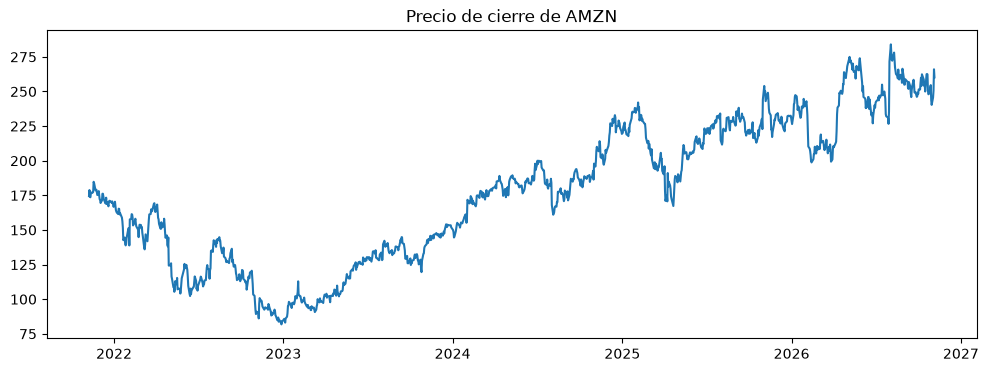

In [3]:
# bajo los datos y quito la ultima vela porque a lo mejor no ha cerrado
df = yf.download(ticker, period=period, interval=interval, multi_level_index=False, auto_adjust=True, progress=False)
df = df.dropna().iloc[:-1]
print(ticker, len(df), "dias, del", df.index[0].date(), "al", df.index[-1].date())

plt.figure(figsize=(12, 4))
plt.plot(df.index, df["Close"])
plt.title(f"Precio de cierre de {ticker}")
plt.show()

Entrenamiento: 877 dias, hasta 2025-05-07
Validacion: 188 dias, hasta 2026-02-05
Prueba: 189 dias, hasta 2026-11-05


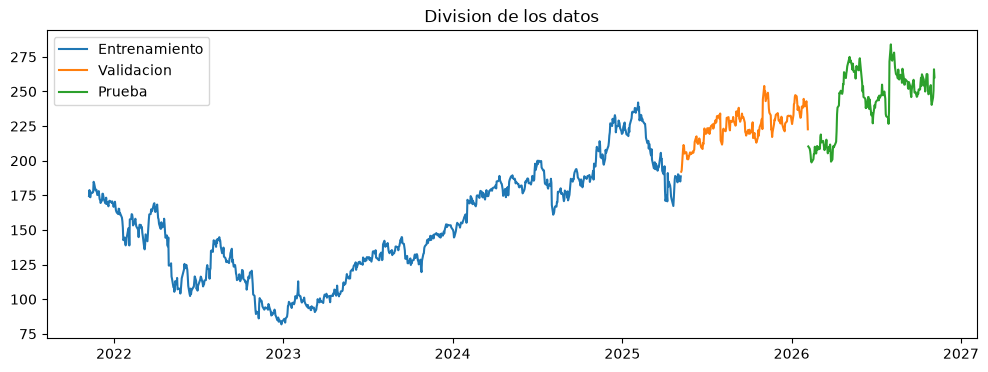

In [4]:
datos = df[variables].copy()
if usar_volumen:
    datos["Volume"] = np.log1p(datos["Volume"])

raw_data = datos.values.astype("float32")  # la columna 0 es el cierre
fechas = datos.index
n_variables = raw_data.shape[1]

# division en orden de tiempo 70/15/15, sin revolver
num_train = int(0.70 * len(raw_data))
num_val = int(0.15 * len(raw_data))
inicio_prueba = num_train + num_val
print("Entrenamiento:", num_train, "dias, hasta", fechas[num_train - 1].date())
print("Validacion:", num_val, "dias, hasta", fechas[inicio_prueba - 1].date())
print("Prueba:", len(raw_data) - inicio_prueba, "dias, hasta", fechas[-1].date())

plt.figure(figsize=(12, 4))
plt.plot(fechas[:num_train], raw_data[:num_train, 0], label="Entrenamiento")
plt.plot(fechas[num_train:inicio_prueba], raw_data[num_train:inicio_prueba, 0], label="Validacion")
plt.plot(fechas[inicio_prueba:], raw_data[inicio_prueba:, 0], label="Prueba")
plt.title("Division de los datos")
plt.legend()
plt.show()

In [5]:
# normalizo solo con entrenamiento para no usar datos del futuro
media = raw_data[:num_train].mean(axis=0)
std = raw_data[:num_train].std(axis=0)
data_norm = (raw_data - media) / std
media_close, std_close = media[0], std[0]
print(f"Media: {media_close:.2f} · Desviacion: {std_close:.2f}")

# cuantos precios de prueba estan fuera de lo que vio la red
cierre_train, cierre_prueba = raw_data[:num_train, 0], raw_data[inicio_prueba:, 0]
fuera = np.mean((cierre_prueba < cierre_train.min()) | (cierre_prueba > cierre_train.max())) * 100
print(f"Precios de prueba fuera del rango de entrenamiento: {fuera:.1f} %")

Media: 151.53 · Desviacion: 38.37
Precios de prueba fuera del rango de entrenamiento: 66.1 %


In [6]:
# ventanas: 30 dias de entrada y el cierre del dia siguiente como objetivo
delay = ventana + horizonte - 1

def crear_dataset(inicio, fin, mezclar=False):
    return keras.utils.timeseries_dataset_from_array(
        data_norm[:-horizonte], targets=data_norm[delay:, 0], sequence_length=ventana,
        batch_size=batch_size, shuffle=mezclar, seed=SEED, start_index=inicio, end_index=fin)

train_ds = crear_dataset(0, num_train - horizonte, mezclar=True)
val_ds = crear_dataset(num_train, inicio_prueba - horizonte)
test_ds = crear_dataset(inicio_prueba, None)

for nombre, ds in [("Entrenamiento", train_ds), ("Validacion", val_ds), ("Prueba", test_ds)]:
    print(nombre, sum(x.shape[0] for x, _ in ds), "ventanas")
x, y = next(iter(train_ds))
print("Forma de un lote:", tuple(x.shape), "->", tuple(y.shape))

Entrenamiento 847 ventanas
Validacion 158 ventanas
Prueba 159 ventanas
Forma de un lote: (32, 30, 1) -> (32,)


## 2. Línea base
"Mañana = hoy": mi predicción es el último cierre de cada ventana. Los errores están en dólares.

In [7]:
def a_arreglos(dataset):
    X = np.concatenate([x.numpy() for x, _ in dataset])
    y = np.concatenate([y.numpy() for _, y in dataset])
    return X, y

X_val, y_val = a_arreglos(val_ds)
X_test, y_test = a_arreglos(test_ds)

error_val = X_val[:, -1, 0] - y_val
error_test = X_test[:, -1, 0] - y_test
mae_base_val = np.abs(error_val).mean() * std_close
mae_base_test = np.abs(error_test).mean() * std_close
rmse_base_test = np.sqrt((error_test ** 2).mean()) * std_close

registro = {"Línea base (mañana = hoy)": {"MAE val": mae_base_val, "MAE prueba": mae_base_test, "RMSE prueba": rmse_base_test}}
print(f"Linea base · MAE prueba: {mae_base_test:.3f} · RMSE prueba: {rmse_base_test:.3f}")

Linea base · MAE prueba: 4.068 · RMSE prueba: 5.683


## 3. Modelo
**LSTM de 32 unidades**

**Por qué:** en mi corrida de la práctica (ALC) fue la recurrente con mayor porcentaje de precision al decir si subira o bajara con 45.9. Ademas en anteriores proyectos ya habia trabajado con la LSTM por lo que es la mas conocida. 

Mientras que la GRU tuvo 44.7 y la bidireccional 44.  

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


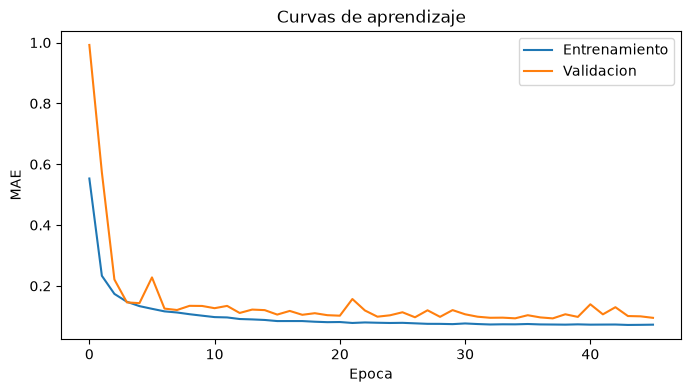

LSTM: 46 epocas · MAE prueba 4.917 (base 4.068) · RMSE prueba 7.041 (base 5.683)


In [8]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(ventana, n_variables))
x = layers.LSTM(32)(inputs)
outputs = layers.Dense(1)(x)
modelo_lstm = keras.Model(inputs, outputs)
modelo_lstm.summary()

modelo_lstm.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
historia = modelo_lstm.fit(train_ds, epochs=50, validation_data=val_ds, callbacks=[parar], shuffle=False, verbose=0)

plt.figure(figsize=(8, 4))
plt.plot(historia.history["mae"], label="Entrenamiento")
plt.plot(historia.history["val_mae"], label="Validacion")
plt.title("Curvas de aprendizaje")
plt.xlabel("Epoca")
plt.ylabel("MAE")
plt.legend()
plt.show()

# regreso los errores a dolares
mae_val = modelo_lstm.evaluate(val_ds, verbose=0)[1] * std_close
mse_test, mae_test = modelo_lstm.evaluate(test_ds, verbose=0)
mae_test, rmse_test = mae_test * std_close, np.sqrt(mse_test) * std_close
registro["LSTM"] = {"MAE val": mae_val, "MAE prueba": mae_test, "RMSE prueba": rmse_test}
print(f"LSTM: {len(historia.history['loss'])} epocas · MAE prueba {mae_test:.3f} (base {mae_base_test:.3f}) · RMSE prueba {rmse_test:.3f} (base {rmse_base_test:.3f})")

## 4. Resultados
Primero el pronóstico de los próximos 30 días hábiles y al final la tabla con los errores.

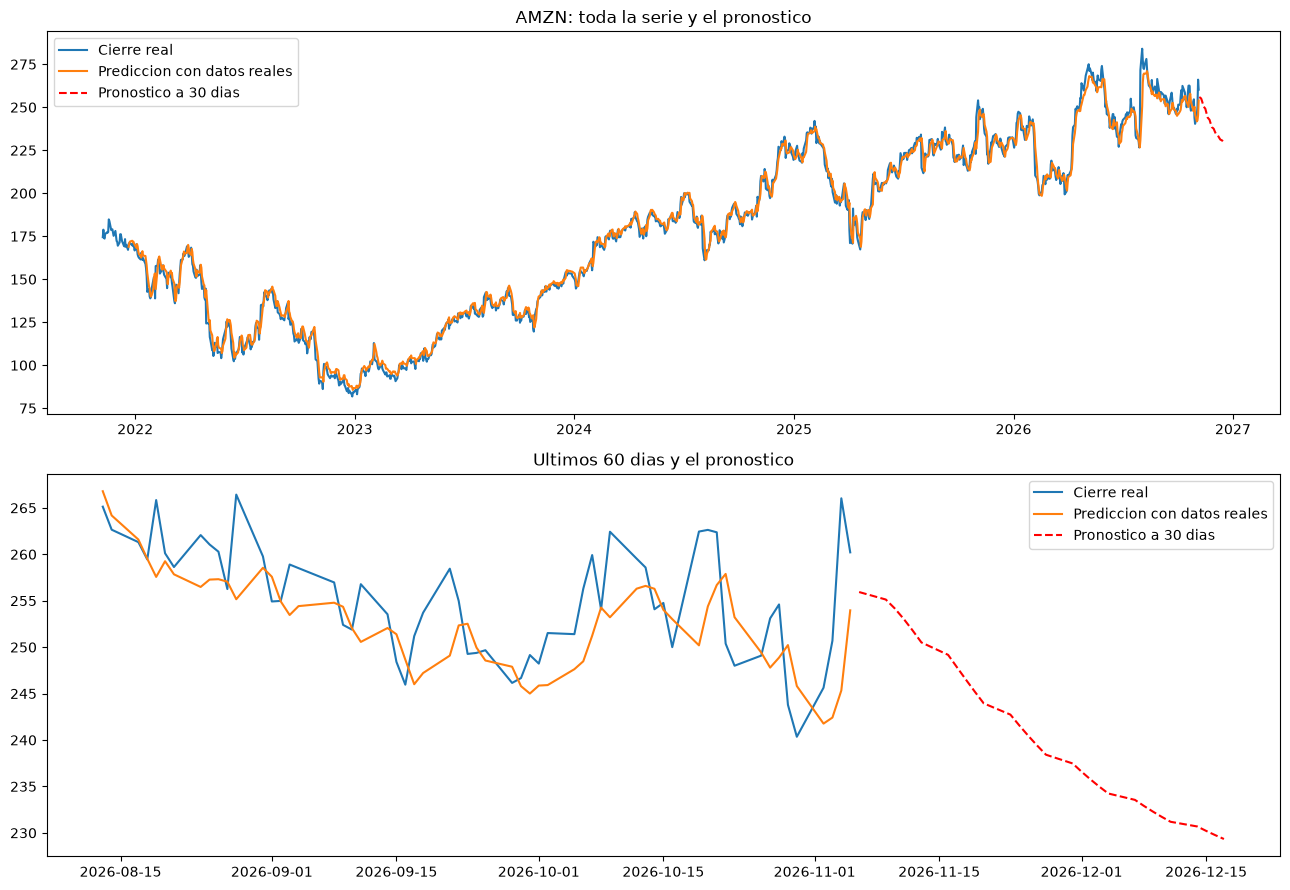

Ultimo cierre (2026-11-05): 260.21
Dia 1 (2026-11-06): 255.94 (-1.6 %)
Dia 30 (2026-12-17): 229.34 (-11.9 %)


In [9]:
def pronosticar_futuro(modelo, pasos=30):
    # cada prediccion entra a la siguiente ventana como si fuera un dato real
    n = len(data_norm)
    serie = np.concatenate([data_norm, np.zeros((pasos, n_variables), dtype="float32")])
    if usar_volumen:
        serie[n:, 1] = data_norm[-ventana:, 1].mean()  # el volumen futuro no se conoce, uso el promedio
    for t in range(n, n + pasos):
        serie[t, 0] = modelo.predict(serie[t - ventana:t][np.newaxis], verbose=0)[0, 0]
    return serie[n:, 0] * std_close + media_close


def dibujar_pronostico(pred_real, futuro):
    fechas_futuro = pd.bdate_range(fechas[-1] + pd.offsets.BDay(1), periods=len(futuro))
    fig, ejes = plt.subplots(2, 1, figsize=(13, 9))
    for eje, desde in [(ejes[0], 0), (ejes[1], len(fechas) - 60)]:
        d = max(desde - delay, 0)
        eje.plot(fechas[desde:], raw_data[desde:, 0], label="Cierre real")
        eje.plot(fechas[delay:][d:], pred_real[d:], label="Prediccion con datos reales")
        eje.plot(fechas_futuro, futuro, "--", color="red", label="Pronostico a 30 dias")
        eje.legend()
    ejes[0].set_title(f"{ticker}: toda la serie y el pronostico")
    ejes[1].set_title("Ultimos 60 dias y el pronostico")
    plt.tight_layout()
    plt.show()

    ultimo_cierre = raw_data[-1, 0]
    print(f"Ultimo cierre ({fechas[-1].date()}): {ultimo_cierre:.2f}")
    print(f"Dia 1 ({fechas_futuro[0].date()}): {futuro[0]:.2f} ({(futuro[0] / ultimo_cierre - 1) * 100:+.1f} %)")
    print(f"Dia 30 ({fechas_futuro[-1].date()}): {futuro[-1]:.2f} ({(futuro[-1] / ultimo_cierre - 1) * 100:+.1f} %)")


pred_real = modelo_lstm.predict(crear_dataset(0, None), verbose=0)[:, 0] * std_close + media_close
futuro_lstm = pronosticar_futuro(modelo_lstm)
dibujar_pronostico(pred_real, futuro_lstm)

In [10]:
resultados = pd.DataFrame(registro).T
resultados.round(3)

,MAE val,MAE prueba,RMSE prueba
Línea base (mañana = hoy),3.119,4.068,5.683
LSTM,3.578,4.917,7.041


## 5. Conclusión
Antes de concluir reviso tres cosas: el retraso de un día, si acierta la dirección y hacia dónde se va el pronóstico.

C:\Users\efrau\OneDrive\Documents\UNIVERSIDAD\SEPTIMO\ML3\ml3\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


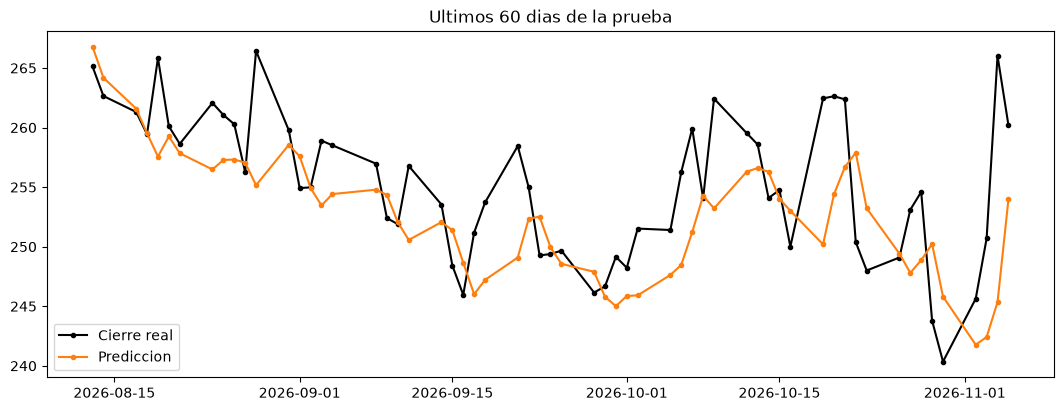

MAE contra el cierre real: 4.917
MAE contra el ultimo cierre que ya conocia: 3.157
Correlacion entre cambio predicho y cambio real: +0.081


In [11]:
# retraso de un dia: reviso si la red solo copia el ultimo cierre
real = y_test * std_close + media_close
ultimo = X_test[:, -1, 0] * std_close + media_close
pred = modelo_lstm.predict(X_test, verbose=0)[:, 0] * std_close + media_close
fechas_obj = fechas[inicio_prueba + delay:][:len(real)]

plt.figure(figsize=(13, 4.5))
plt.plot(fechas_obj[-60:], real[-60:], "o-", color="black", markersize=3, label="Cierre real")
plt.plot(fechas_obj[-60:], pred[-60:], "o-", color="tab:orange", markersize=3, label="Prediccion")
plt.title("Ultimos 60 dias de la prueba")
plt.legend()
plt.show()

print(f"MAE contra el cierre real: {np.mean(np.abs(pred - real)):.3f}")
print(f"MAE contra el ultimo cierre que ya conocia: {np.mean(np.abs(pred - ultimo)):.3f}")
print(f"Correlacion entre cambio predicho y cambio real: {np.corrcoef(pred - ultimo, real - ultimo)[0, 1]:+.3f}")

In [12]:
# exactitud direccional: si acierta cuando sube o baja
X_train, y_train = a_arreglos(crear_dataset(0, num_train - horizonte))
mayoria_sube = (y_train > X_train[:, -1, 0]).mean() >= 0.5
real_sube = real > ultimo
hoy_subio = X_test[:, -1, 0] > X_test[:, -2, 0]

print(f"Moneda al aire: 50.0 %")
print(f"Siempre {'sube' if mayoria_sube else 'baja'}: {np.mean(real_sube == mayoria_sube) * 100:.1f} %")
print(f"Igual que hoy: {np.mean(real_sube == hoy_subio) * 100:.1f} %")
print(f"LSTM: {np.mean((pred > ultimo) == real_sube) * 100:.1f} %")

margen = 100 / np.sqrt(len(real))
print(f"Con {len(real)} ventanas, entre {50 - margen:.0f} % y {50 + margen:.0f} % todavia puede ser azar")

Moneda al aire: 50.0 %
Siempre sube: 49.1 %
Igual que hoy: 49.7 %
LSTM: 57.2 %
Con 159 ventanas, entre 42 % y 58 % todavia puede ser azar


In [13]:
# sesgo del pronostico: hacia donde se va
print(f"Ultimo cierre real: {raw_data[-1, 0]:.2f}")
print(f"Pronostico a 30 dias: {futuro_lstm[-1]:.2f} ({(futuro_lstm[-1] / raw_data[-1, 0] - 1) * 100:+.1f} %)")
print(f"Promedio de entrenamiento: {media_close:.2f}")
print(f"Maximo de entrenamiento: {raw_data[:num_train, 0].max():.2f}")

Ultimo cierre real: 260.21
Pronostico a 30 dias: 229.34 (-11.9 %)
Promedio de entrenamiento: 151.53
Maximo de entrenamiento: 242.06


**¿Subirá o bajará en los próximos 30 días?** 

- **Pronóstico:** la LSTM dice que AMZN bajara de 260.5 que fue el ultimo valor conocido, a 229.34, un -11.9% en los proximos 30 dias.
- **Retraso de un día:** La prediccion sigue tardando en actuar, no parece que funcionara el mañana = hoy, porque la red sigue "copiando" el movimiento del rendimiento
- **Dirección:** la LSTM acierta 57.2 %, que es mejor de lo que salio con el otro ticker, posiblemente por el movimiento menos caotico pero aun asi, sigue siendo un porcentaja de azar. 
- **Sesgo recursivo:** Como el ultimo movimiento real fue hacia abajo y la red copio ese movimiento, se creo un sesgo donde va hacia abajo llegando a ese -11.9% de rendimiento
- **Confianza: baja.** El resultado muestra el sesgo del modelo, no el futuro de la acción. Que la red no le gane a la línea base es lo esperado: el precio de mañana depende de noticias que hoy no existen.